Prompt: ## Step 1: Load the data **Chat:**Load credit_card_fraud_10k.csv into a pandas DataFrame and report its shape,column types, missing values and duplicate rows. Also show the first few rows,the fraud count and fraud rate, and the value ranges of each numeric column.Add assertions that check the shape is (10000, 10) and the fraud count is 151.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Load the CSV from the project directory.
csv_path = Path("credit_card_fraud_10k.csv")
df = pd.read_csv(csv_path)

# Validate the expected dataset dimensions and number of fraud cases.
assert df.shape == (10000, 10), f"Unexpected shape: {df.shape}"
fraud_count = int(df["is_fraud"].sum())
assert fraud_count == 151, f"Unexpected fraud count: {fraud_count}"

print(f"Shape: {df.shape}")

print("\nColumn types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nMissing values by column:")
display(df.isna().sum().rename("missing_values").to_frame())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nFirst five rows:")
display(df.head())

fraud_rate = df["is_fraud"].mean()
print(f"Fraud count: {fraud_count}")
print(f"Fraud rate: {fraud_rate:.2%}")

print("\nNumeric column ranges:")
numeric_ranges = df.select_dtypes(include="number").agg(["min", "max"]).T
numeric_ranges.columns = ["minimum", "maximum"]
display(numeric_ranges)

Shape: (10000, 10)

Column types:


,dtype
transaction_id,int64
amount,float64
transaction_hour,int64
merchant_category,str
foreign_transaction,int64
location_mismatch,int64
device_trust_score,int64
velocity_last_24h,int64
cardholder_age,int64
is_fraud,int64



Missing values by column:


,missing_values
transaction_id,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0



Duplicate rows: 0

First five rows:


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


Fraud count: 151
Fraud rate: 1.51%

Numeric column ranges:


,minimum,maximum
transaction_id,1.0,10000.00
amount,0.0,1471.04
transaction_hour,0.0,23.00
foreign_transaction,0.0,1.00
location_mismatch,0.0,1.00
device_trust_score,25.0,99.00
velocity_last_24h,0.0,9.00
cardholder_age,18.0,69.00
is_fraud,0.0,1.00


## Step 2: Exploratory data analysis
 
**Chat:**
Explore how fraud relates to each feature using seaborn and pandas. Show the
overall fraud count and rate. Plot fraud RATE (not raw counts) by merchant
category, by hour of day, by foreign_transaction, and by location_mismatch,
with a dashed line for the overall 1.5% rate. For continuous features (amount,
device_trust_score, velocity_last_24h, cardholder_age) compare fraud vs
non-fraud with boxplots or KDE plots, and also show fraud rate by binned
value (quantile bins). Finish with a table of mean/median per feature by class
and a correlation of each numeric feature with is_fraud.

Overall fraud count: 151
Overall fraud rate: 1.51%


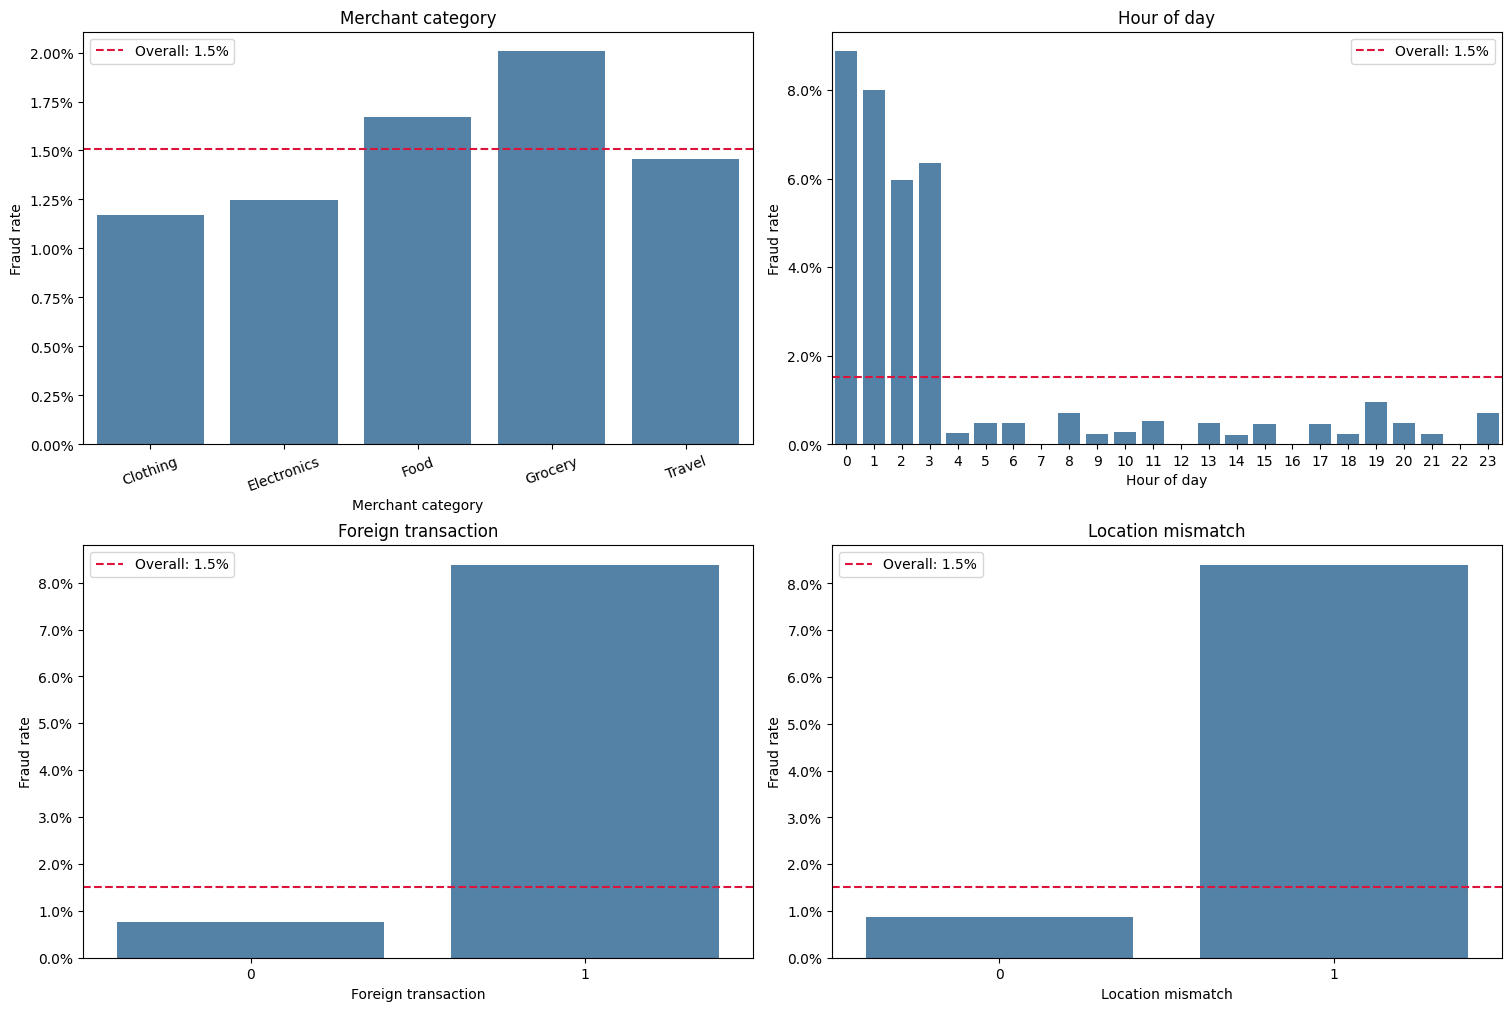

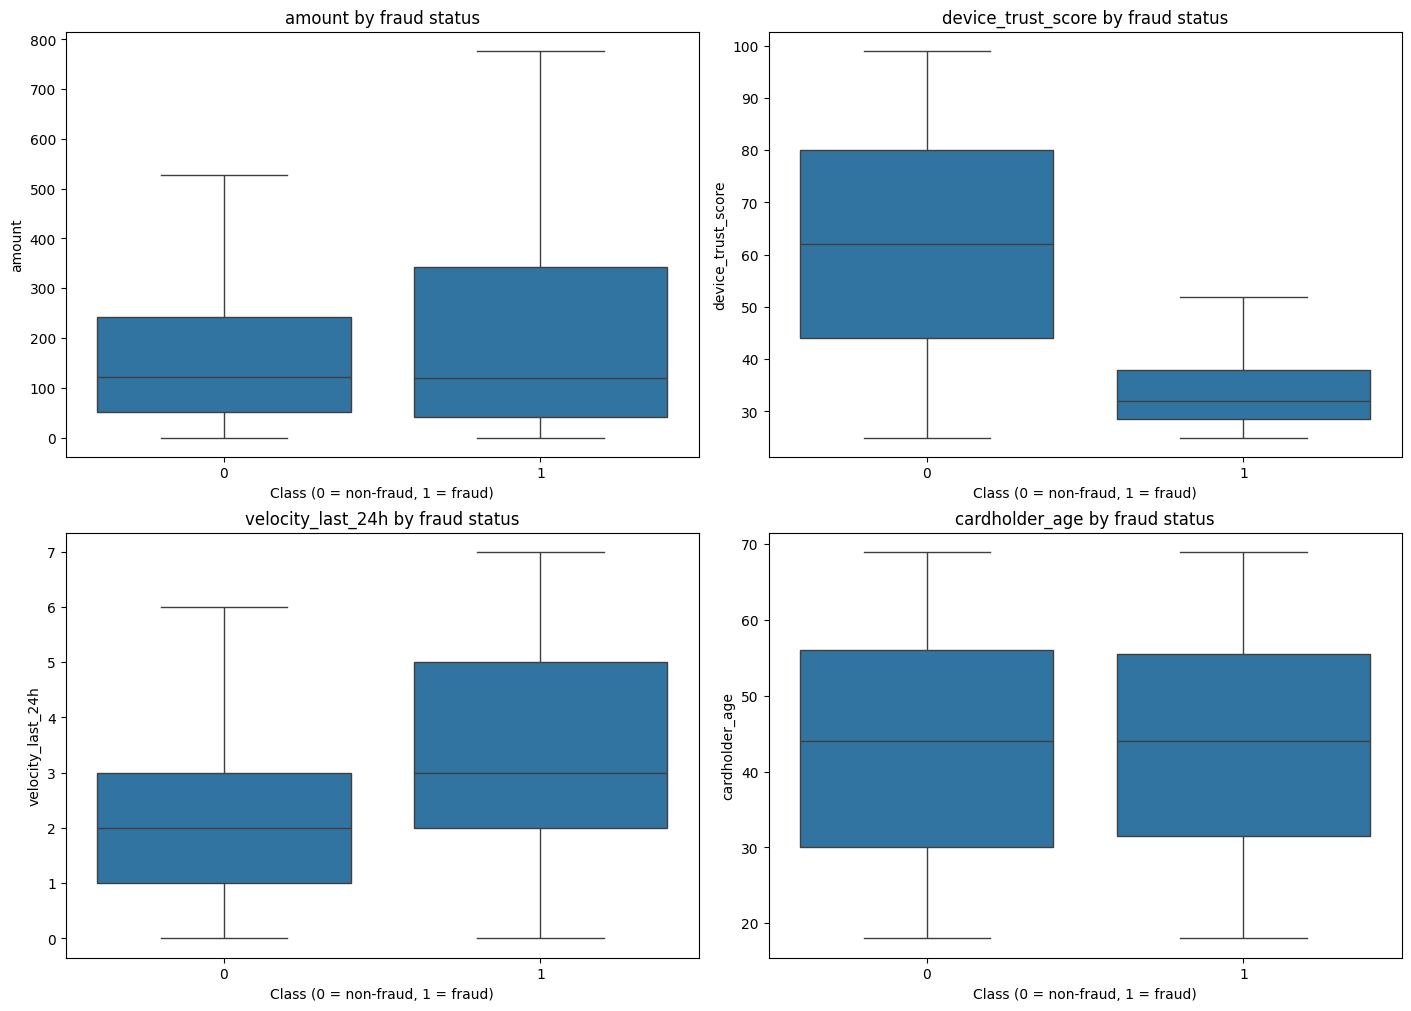

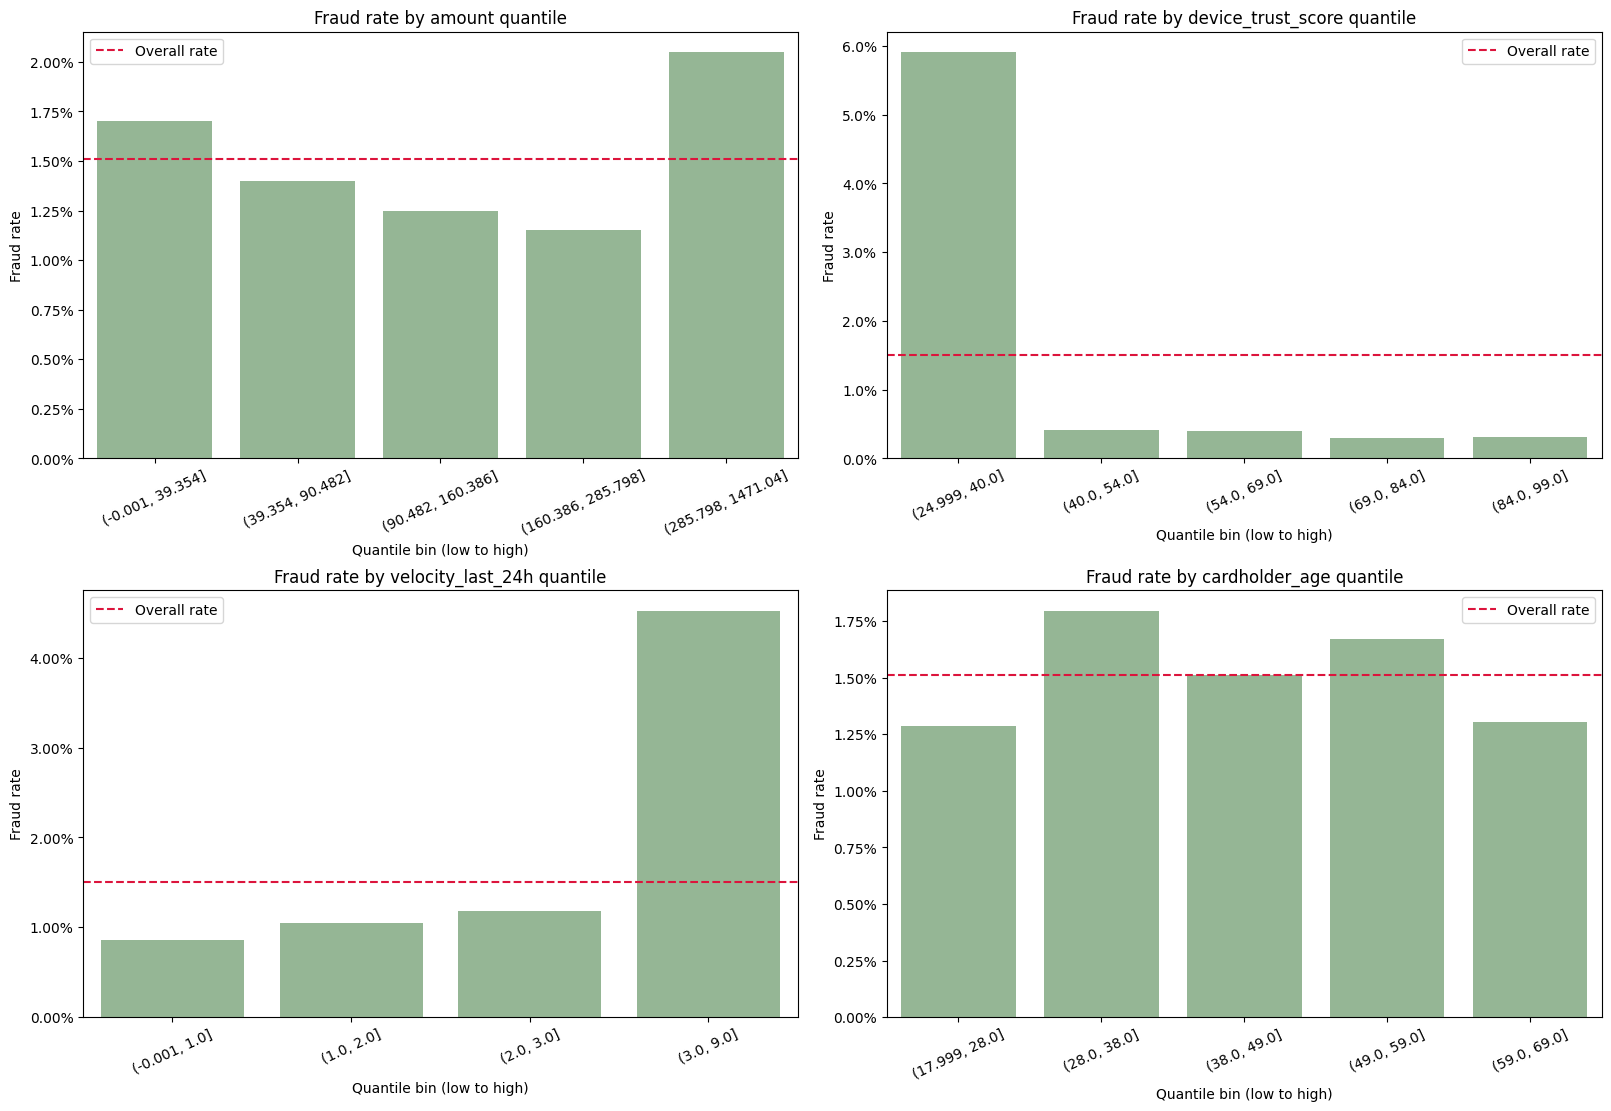

Mean and median of numeric features by class:


,Non-fraud,Fraud
amount mean,175.333015,216.182980
amount median,122.110000,118.940000
transaction_hour mean,11.712154,3.841060
transaction_hour median,12.000000,2.000000
foreign_transaction mean,0.090974,0.543046
foreign_transaction median,0.000000,1.000000
location_mismatch mean,0.079704,0.476821
location_mismatch median,0.000000,0.000000
device_trust_score mean,62.165804,37.867550
device_trust_score median,62.000000,32.000000


Correlation of numeric features with is_fraud:


,correlation with is_fraud
foreign_transaction,0.185597
location_mismatch,0.173009
velocity_last_24h,0.103413
amount,0.028404
cardholder_age,-0.000590
device_trust_score,-0.137913
transaction_hour,-0.138665


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

overall_fraud_count = int(df["is_fraud"].sum())
overall_fraud_rate = df["is_fraud"].mean()
print(f"Overall fraud count: {overall_fraud_count:,}")
print(f"Overall fraud rate: {overall_fraud_rate:.2%}")

# Plot fraud rates rather than event counts for these groups.
group_columns = [
    ("merchant_category", "Merchant category"),
    ("transaction_hour", "Hour of day"),
    ("foreign_transaction", "Foreign transaction"),
    ("location_mismatch", "Location mismatch"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
for ax, (column, title) in zip(axes.flat, group_columns):
    fraud_rates = (
        df.groupby(column, observed=True)["is_fraud"]
        .mean()
        .rename("fraud_rate")
        .reset_index()
    )
    if column == "transaction_hour":
        fraud_rates = fraud_rates.sort_values(column)
    sns.barplot(
        data=fraud_rates,
        x=column,
        y="fraud_rate",
        color="steelblue",
        errorbar=None,
        ax=ax,
    )
    ax.axhline(
        overall_fraud_rate,
        color="crimson",
        linestyle="--",
        label=f"Overall: {overall_fraud_rate:.1%}",
    )
    ax.set(title=title, xlabel=title, ylabel="Fraud rate")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend()
    if column == "merchant_category":
        ax.tick_params(axis="x", rotation=20)
plt.show()

continuous_features = [
    "amount",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age",
]

# Compare feature distributions for non-fraud and fraud transactions.
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for ax, feature in zip(axes.flat, continuous_features):
    sns.boxplot(data=df, x="is_fraud", y=feature, showfliers=False, ax=ax)
    ax.set(title=f"{feature} by fraud status", xlabel="Class (0 = non-fraud, 1 = fraud)")
plt.show()

# Calculate and plot fraud rates across five quantile bins for each feature.
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for ax, feature in zip(axes.flat, continuous_features):
    binned = df[[feature, "is_fraud"]].copy()
    binned["quantile_bin"] = pd.qcut(binned[feature], q=5, duplicates="drop")
    fraud_by_bin = (
        binned.groupby("quantile_bin", observed=True)["is_fraud"]
        .agg(fraud_rate="mean", transactions="size")
        .reset_index()
    )
    fraud_by_bin["quantile_bin"] = fraud_by_bin["quantile_bin"].astype(str)
    sns.barplot(
        data=fraud_by_bin,
        x="quantile_bin",
        y="fraud_rate",
        color="darkseagreen",
        errorbar=None,
        ax=ax,
    )
    ax.axhline(overall_fraud_rate, color="crimson", linestyle="--", label="Overall rate")
    ax.set(title=f"Fraud rate by {feature} quantile", xlabel="Quantile bin (low to high)", ylabel="Fraud rate")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
plt.show()

# Numeric predictors exclude the transaction identifier and fraud target.
numeric_features = [
    column
    for column in df.select_dtypes(include="number").columns
    if column not in {"transaction_id", "is_fraud"}
]

print("Mean and median of numeric features by class:")
class_summary = df.groupby("is_fraud")[numeric_features].agg(["mean", "median"])
class_summary.columns = [
    f"{feature} {statistic}" for feature, statistic in class_summary.columns
]
class_summary = class_summary.T
class_summary.columns = ["Non-fraud", "Fraud"]
display(class_summary)

print("Correlation of numeric features with is_fraud:")
fraud_correlations = (
    df[numeric_features + ["is_fraud"]]
    .corr(numeric_only=True)["is_fraud"]
    .drop("is_fraud")
    .sort_values(ascending=False)
    .rename("correlation with is_fraud")
    .to_frame()
)
display(fraud_correlations)

## Step 3: Clean and prepare
 
**Chat:**

Prepare the data for modeling. Drop transaction_id (identifier, not a feature),

separate the target is_fraud, and make a stratified 80/20 train/test split with

a fixed random_state. Print fraud counts and rates in train and test. Build a

scikit-learn ColumnTransformer that one-hot encodes merchant_category, standardizes

the continuous numeric columns, and passes the binary columns through unchanged.

Wrap it with the model in a Pipeline so that every step is fitted on training data

only. Then show where each step is fitted: print the fitted scaler means and the

encoder categories, and compare them with the training-set and full-data means.

Finally report 5-fold stratified cross-validation on the training set using a

baseline logistic regression (class_weight="balanced") with accuracy, balanced

accuracy, precision, recall, F1, ROC AUC and PR AUC. Do not touch the test set.
 

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

target_column = "is_fraud"
categorical_columns = ["merchant_category"]
continuous_columns = [
    "amount",
    "transaction_hour",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age",
]
binary_columns = ["foreign_transaction", "location_mismatch"]

# Drop the identifier and separate the target before splitting.
X = df.drop(columns=["transaction_id", target_column])
y = df[target_column]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

split_summary = pd.DataFrame(
    {
        "rows": [len(y_train), len(y_test)],
        "non_fraud_count": [(y_train == 0).sum(), (y_test == 0).sum()],
        "fraud_count": [(y_train == 1).sum(), (y_test == 1).sum()],
        "fraud_rate": [y_train.mean(), y_test.mean()],
    },
    index=["Train", "Test"],
)
split_summary["fraud_rate"] = split_summary["fraud_rate"].map(lambda rate: f"{rate:.2%}")
print("Stratified train/test split (80/20, random_state=42):")
display(split_summary)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("continuous", StandardScaler(), continuous_columns),
        ("binary", "passthrough", binary_columns),
    ],
    remainder="drop",
)
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ]
)

# Fit the inspection pipeline on the training partition only.
baseline_pipeline.fit(X_train, y_train)
fitted_preprocessor = baseline_pipeline.named_steps["preprocessor"]
fitted_scaler = fitted_preprocessor.named_transformers_["continuous"]
fitted_encoder = fitted_preprocessor.named_transformers_["categorical"]

print("Pipeline steps fitted on training data:")
for step_name, fitted_step in baseline_pipeline.named_steps.items():
    print(f"- {step_name}: {fitted_step.__class__.__name__}")

fit_locations = pd.DataFrame(
    [
        {
            "step": "OneHotEncoder",
            "fit data": "X_train['merchant_category']",
            "what is learned": "Merchant categories present in training data",
        },
        {
            "step": "StandardScaler",
            "fit data": "X_train[continuous_columns]",
            "what is learned": "Training means and standard deviations",
        },
        {
            "step": "Binary passthrough",
            "fit data": "No fitting; binary columns are passed through unchanged",
            "what is learned": "Nothing",
        },
        {
            "step": "LogisticRegression",
            "fit data": "Transformed X_train and y_train",
            "what is learned": "Model coefficients and intercept",
        },
        {
            "step": "Cross-validation",
            "fit data": "Pipeline is refit on each fold's training rows only",
            "what is learned": "Fold-specific preprocessing and model parameters",
        },
    ]
).set_index("step")
print("Where each transformer and model is fitted:")
display(fit_locations)

scaler_means = pd.Series(fitted_scaler.mean_, index=continuous_columns)
mean_comparison = pd.DataFrame(
    {
        "fitted scaler mean (train)": scaler_means,
        "training-set mean": X_train[continuous_columns].mean(),
        "full-data mean (diagnostic only)": X[continuous_columns].mean(),
    }
)
print("Fitted scaler means compared with training and full-data feature means:")
display(mean_comparison)

print("One-hot encoder categories learned from training data:")
for column, categories in zip(categorical_columns, fitted_encoder.categories_):
    print(f"{column}: {categories.tolist()}")

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    return_train_score=False,
)
cv_fold_scores = pd.DataFrame(
    {metric: cv_results[f"test_{metric}"] for metric in scoring}
)
print("Five-fold stratified cross-validation scores on the training set:")
display(cv_fold_scores)
cv_summary = cv_fold_scores.agg(["mean", "std"]).T
cv_summary.columns = ["mean", "standard_deviation"]
print("Cross-validation metric mean and standard deviation:")
display(cv_summary)


Stratified train/test split (80/20, random_state=42):


,rows,non_fraud_count,fraud_count,fraud_rate
Train,8000,7879,121,1.51%
Test,2000,1970,30,1.50%


Pipeline steps fitted on training data:
- preprocessor: ColumnTransformer
- model: LogisticRegression
Where each transformer and model is fitted:


,fit data,what is learned
step,,
OneHotEncoder,X_train['merchant_category'],Merchant categories present in training data
StandardScaler,X_train[continuous_columns],Training means and standard deviations
Binary passthrough,No fitting; binary columns are passed through ...,Nothing
LogisticRegression,Transformed X_train and y_train,Model coefficients and intercept
Cross-validation,Pipeline is refit on each fold's training rows...,Fold-specific preprocessing and model parameters


Fitted scaler means compared with training and full-data feature means:


,fitted scaler mean (train),training-set mean,full-data mean (diagnostic only)
amount,175.361465,175.361465,175.949849
transaction_hour,11.588625,11.588625,11.593300
device_trust_score,61.994000,61.994000,61.798900
velocity_last_24h,2.007875,2.007875,2.008900
cardholder_age,43.407750,43.407750,43.468700


One-hot encoder categories learned from training data:
merchant_category: ['Clothing', 'Electronics', 'Food', 'Grocery', 'Travel']
Five-fold stratified cross-validation scores on the training set:


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
0,0.953125,0.955690,0.237113,0.958333,0.380165,0.989187,0.684909
1,0.964375,0.961400,0.291139,0.958333,0.446602,0.990139,0.593351
2,0.956250,0.957276,0.250000,0.958333,0.396552,0.988632,0.560585
3,0.962500,0.960448,0.280488,0.958333,0.433962,0.993893,0.664278
4,0.954375,0.976825,0.255102,1.000000,0.406504,0.996241,0.827331


Cross-validation metric mean and standard deviation:


,mean,standard_deviation
accuracy,0.958125,0.005019
balanced_accuracy,0.962328,0.008429
precision,0.262768,0.022354
recall,0.966667,0.018634
f1,0.412757,0.027199
roc_auc,0.991618,0.003300
pr_auc,0.666091,0.103415


Prompt: Show where each step is fitted and explain and where is the scaling?

Yes—this uses scikit-learn’s Pipeline.

Encoding: OneHotEncoder encodes merchant_category.
Scaling: StandardScaler scales amount, transaction_hour, device_trust_score, velocity_last_24h, and cardholder_age.
Both are in the ColumnTransformer, which is the preprocessing step in the Pipeline. They are fitted on training data; the binary flags pass through unchanged.
Resampling: No oversampling or undersampling is performed. Instead, logistic regression uses class_weight="balanced" to account for the rare fraud class (model configuration). Stratified cross-validation preserves the class proportions in each fold.

## Step 4: Build models

All models use class weighting and no resampling. With `class_weight="balanced"`, scikit-learn gives the minority fraud class more weight based on the class frequencies in the data used to fit each model.

- **Logistic regression:** `class_weight="balanced"` increases the penalty for misclassifying fraud cases.
- **SVC:** `class_weight="balanced"` applies a larger class-specific penalty (C) to fraud errors.
- **Random forest:** `class_weight="balanced"` weights fraud cases more heavily when fitting the trees.
- **Gradient boosting:** `HistGradientBoostingClassifier(class_weight="balanced")` uses class weights in its loss; this histogram-based estimator supports the same weighting approach.

Each model is placed after a fresh copy of the Step 3 preprocessor using `make_pipeline()`. Pipelines are fitted on `X_train` and `y_train`; cross-validation refits the entire pipeline within each training fold. The test set is not used.

In [5]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

model_estimators = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
    ),
    "SVC": SVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        max_iter=100,
        random_state=42,
    ),
}

fitted_pipelines = {}
cv_results_by_model = {}
for model_name, estimator in model_estimators.items():
    pipeline = make_pipeline(clone(preprocessor), clone(estimator))
    pipeline.fit(X_train, y_train)
    fitted_pipelines[model_name] = pipeline
    cv_results_by_model[model_name] = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=stratified_cv,
        scoring=scoring,
        return_train_score=False,
    )

model_cv_summary = pd.DataFrame(
    {
        model_name: {
            metric: results[f"test_{metric}"].mean()
            for metric in scoring
        }
        for model_name, results in cv_results_by_model.items()
    }
).T
print("Mean five-fold stratified CV scores on the training set:")
display(model_cv_summary.round(3))
print("Per-fold scores are stored in cv_results_by_model; fitted training pipelines are stored in fitted_pipelines.")

Mean five-fold stratified CV scores on the training set:


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.958,0.962,0.263,0.967,0.413,0.992,0.666
SVC,0.989,0.921,0.613,0.850,0.711,0.996,0.822
Random Forest,0.995,0.839,1.000,0.678,0.807,1.000,0.979
Gradient Boosting,0.998,0.946,0.974,0.892,0.929,0.999,0.979


Per-fold scores are stored in cv_results_by_model; fitted training pipelines are stored in fitted_pipelines.


How does each model handle class imbalance? All four models use class_weight="balanced". This gives fraud examples more influence during training because they are much rarer; it changes how costly mistakes are, but does not add, remove, or duplicate transactions.

Logistic regression: Weights fraud cases more in its loss function.
SVC: Applies a larger penalty to misclassifying fraud cases.
Random forest: Gives fraud cases more influence when building its decision trees.
Histogram-based gradient boosting: Gives fraud cases more influence in the model’s training loss.
The weights are calculated from the labels in each training fold, so no resampling is used and the test set stays out of model training.

## Step 5: Report model performance

ROC AUC measures how well scores rank fraud above legitimate transactions across thresholds. PR AUC (average precision) focuses on precision and recall for the rare fraud class, so it is more revealing when accuracy and ROC AUC look strong despite weak fraud detection. A random classifier's PR AUC baseline is the fraud prevalence.

The best classifier is selected using mean training cross-validation PR AUC only. The test set is used afterward for final evaluation and plots; no model or threshold is selected using test results.

Prompt: ## Step 5: Report model performance
 
**Chat:**

Create a summary table of all models with accuracy, balanced accuracy, fraud

precision, fraud recall, fraud F1, ROC AUC and PR AUC (average precision), on the

test set and in 5-fold CV (mean and std). Add a "never predicts fraud" dummy

baseline row. Compare ROC AUC with PR AUC per model, including the PR AUC of a

random classifier (the fraud rate). Choose the best model using the CV results

only, not the test set. Show the confusion matrix of that model at the default 0.5

threshold, and plot precision-recall curves for all models on the test set with

the random-classifier baseline. Use the test set for evaluation only: no fitting,

no threshold or model selection on it.
 

Model ranking by mean training CV PR AUC (selection uses CV only):


,mean CV PR AUC
Gradient Boosting,0.979478
Random Forest,0.979280
SVC,0.821584
Logistic Regression,0.666091


Selected model: Gradient Boosting
Test metrics and five-fold training CV mean/std:


Test                                                 \
                     Accuracy Balanced accuracy Fraud precision Fraud recall   
Logistic Regression    0.9575            0.9784          0.2609       1.0000   
SVC                    0.9855            0.8777          0.5111       0.7667   
Random Forest          0.9980            0.9333          1.0000       0.8667   
Gradient Boosting      0.9995            0.9833          1.0000       0.9667   
Never predicts fraud   0.9850            0.5000          0.0000       0.0000   

                                                                  CV mean  \
                     Fraud F1 ROC AUC PR AUC (average precision) Accuracy   
Logistic Regression    0.4138  0.9933                     0.7413   0.9581   
SVC                    0.6133  0.9936                     0.8098   0.9895   
Random Forest          0.9286  1.0000                     1.0000   0.9951   
Gradient Boosting      0.9831  1.0000                     1.0000   0.9980   
Never predicts fraud   0.0000  0.5000                     0.0150   0.9849   

                                                        ...                   \
                     Balanced accuracy Fraud precision  ... Fraud F1 ROC AUC   
Logistic Regression             0.9623          0.2628  ...   0.4128  0.9916   
SVC                             0.9210          0.6133  ...   0.7110  0.9961   
Random Forest                   0.8390          1.0000  ...   0.8066  0.9995   
Gradient Boosting               0.9458          0.9741  ...   0.9295  0.9993   
Never predicts fraud            0.5000          0.0000  ...   0.0000  0.5000   

                                                  CV std                    \
                     PR AUC (average precision) Accuracy Balanced accuracy   
Logistic Regression                      0.6661   0.0050            0.0084   
SVC                                      0.8216   0.0027            0.0436   
Random Forest                            0.9793   0.0010            0.0330   
Gradient Boosting                        0.9795   0.0010            0.0380   
Never predicts fraud                     0.0151   0.0003            0.0000   

                                                                    \
                     Fraud precision Fraud recall Fraud F1 ROC AUC   
Logistic Regression           0.0224       0.0186   0.0272  0.0033   
SVC                           0.0691       0.0869   0.0666  0.0021   
Random Forest                 0.0000       0.0660   0.0478  0.0005   
Gradient Boosting             0.0238       0.0761   0.0395  0.0007   
Never predicts fraud          0.0000       0.0000   0.0000  0.0000   

                                                 
                     PR AUC (average precision)  
Logistic Regression                      0.1034  
SVC                                      0.1139  
Random Forest                            0.0221  
Gradient Boosting                        0.0089  
Never predicts fraud                     0.0003  

[5 rows x 21 columns]

Random-classifier PR AUC baseline on test data (fraud rate): 0.0150
Random-classifier ROC AUC reference: 0.5000
Mean fold-level random PR AUC baseline: 0.0151
ROC AUC may remain high when negatives dominate; PR AUC shows how well the model retrieves fraud and should be compared with the low prevalence baseline.
Confusion matrix for CV-selected Gradient Boosting at threshold 0.5:


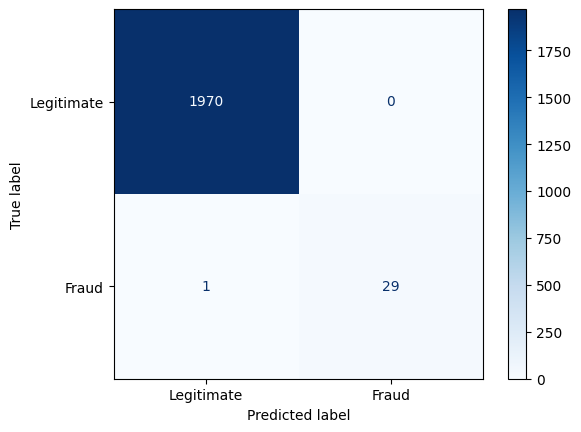

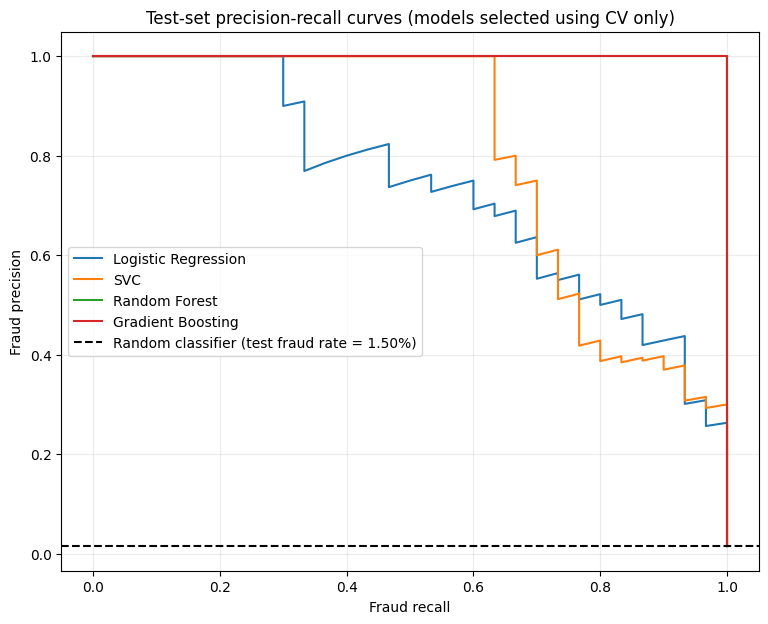

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
import matplotlib.pyplot as plt

# Choose by training CV PR AUC before accessing test metrics.
cv_pr_auc_means = {
    model_name: results["test_pr_auc"].mean()
    for model_name, results in cv_results_by_model.items()
}
cv_model_ranking = pd.Series(cv_pr_auc_means, name="mean CV PR AUC").sort_values(
    ascending=False
)
best_model_name = cv_model_ranking.index[0]
print("Model ranking by mean training CV PR AUC (selection uses CV only):")
display(cv_model_ranking.to_frame())
print(f"Selected model: {best_model_name}")

# Never-predict-fraud baseline. Define zero precision/F1 explicitly for this row.
dummy_pipeline = make_pipeline(DummyClassifier(strategy="most_frequent"))
dummy_pipeline.fit(X_train, y_train)
dummy_scoring = scoring.copy()
dummy_scoring["precision"] = make_scorer(precision_score, zero_division=0)
dummy_scoring["f1"] = make_scorer(f1_score, zero_division=0)
dummy_cv_results = cross_validate(
    make_pipeline(DummyClassifier(strategy="most_frequent")),
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=dummy_scoring,
    return_train_score=False,
)

def positive_class_scores(pipeline, X_eval):
    estimator = pipeline.steps[-1][1]
    positive_index = list(estimator.classes_).index(1)
    if hasattr(estimator, "predict_proba"):
        return pipeline.predict_proba(X_eval)[:, positive_index]
    if hasattr(estimator, "decision_function"):
        scores = pipeline.decision_function(X_eval)
        return scores if positive_index == 1 else -scores
    raise TypeError(f"{estimator.__class__.__name__} has no probability or decision scores")

def calculate_metrics(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
    }

# Evaluate the four fitted training pipelines and dummy baseline on the test set.
pipelines_to_evaluate = {**fitted_pipelines, "Never predicts fraud": dummy_pipeline}
test_metrics_by_model = {}
test_scores_by_model = {}
for model_name, pipeline in pipelines_to_evaluate.items():
    test_predictions = pipeline.predict(X_test)
    test_scores = positive_class_scores(pipeline, X_test)
    test_scores_by_model[model_name] = test_scores
    test_metrics_by_model[model_name] = calculate_metrics(
        y_test, test_predictions, test_scores
    )

all_cv_results = {**cv_results_by_model, "Never predicts fraud": dummy_cv_results}
metric_labels = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "precision": "Fraud precision",
    "recall": "Fraud recall",
    "f1": "Fraud F1",
    "roc_auc": "ROC AUC",
    "pr_auc": "PR AUC (average precision)",
}
performance_columns = pd.MultiIndex.from_product(
    [["Test" , "CV mean", "CV std"], metric_labels.values()]
)
performance_summary = pd.DataFrame(
    index=pipelines_to_evaluate,
    columns=performance_columns,
    dtype=float,
)
for model_name in pipelines_to_evaluate:
    for metric, label in metric_labels.items():
        cv_scores = all_cv_results[model_name][f"test_{metric}"]
        performance_summary.loc[model_name, ("Test", label)] = test_metrics_by_model[
            model_name
        ][metric]
        performance_summary.loc[model_name, ("CV mean", label)] = cv_scores.mean()
        performance_summary.loc[model_name, ("CV std", label)] = cv_scores.std(ddof=1)
print("Test metrics and five-fold training CV mean/std:")
display(performance_summary.round(4))

test_fraud_rate = y_test.mean()
cv_random_pr_baseline = dummy_cv_results["test_pr_auc"].mean()
print(f"Random-classifier PR AUC baseline on test data (fraud rate): {test_fraud_rate:.4f}")
print(f"Random-classifier ROC AUC reference: 0.5000")
print(f"Mean fold-level random PR AUC baseline: {cv_random_pr_baseline:.4f}")
print(
    "ROC AUC may remain high when negatives dominate; PR AUC shows how well the model "
    "retrieves fraud and should be compared with the low prevalence baseline."
)

# The selected model's prediction uses the default 0.5 probability cutoff.
best_pipeline = fitted_pipelines[best_model_name]
best_estimator = best_pipeline.steps[-1][1]
if not hasattr(best_estimator, "predict_proba"):
    raise TypeError("The CV-selected model does not expose probabilities for a 0.5 cutoff")
best_positive_index = list(best_estimator.classes_).index(1)
best_test_probabilities = best_pipeline.predict_proba(X_test)[:, best_positive_index]
best_test_predictions = (best_test_probabilities >= 0.5).astype(int)
confusion = confusion_matrix(y_test, best_test_predictions, labels=[0, 1])
print(f"Confusion matrix for CV-selected {best_model_name} at threshold 0.5:")
ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["Legitimate", "Fraud"],
).plot(cmap="Blues", values_format="d")
plt.show()

plt.figure(figsize=(9, 7))
for model_name in fitted_pipelines:
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        test_scores_by_model[model_name],
    )
    plt.plot(recall_values, precision_values, label=model_name)
plt.axhline(
    test_fraud_rate,
    color="black",
    linestyle="--",
    label=f"Random classifier (test fraud rate = {test_fraud_rate:.2%})",
)
plt.xlabel("Fraud recall")
plt.ylabel("Fraud precision")
plt.title("Test-set precision-recall curves (models selected using CV only)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

How do I read the precision-recall curve? Recall (horizontal axis): Of all actual fraud cases, what fraction did the model catch?
Precision (vertical axis): Of all transactions the model flagged as fraud, what fraction really were fraud?
Each point represents a different cutoff. Lowering the cutoff usually catches more fraud (higher recall) but also flags more legitimate transactions (lower precision). Curves closer to the upper-right corner generally indicate a better tradeoff. The dashed line at 1.5% is the precision expected from random guessing at this dataset’s fraud rate.

The chosen Gradient Boosting model’s test confusion matrix corresponds to 96.7% recall (29 of 30 fraud cases caught) and 100% precision (no legitimate transactions falsely flagged) at the 0.5 cutoff. The curve shows how that tradeoff changes at other cutoffs; it was not used to tune the model. Since the test set contains only 30 fraud cases, treat the results as an estimate rather than a guarantee.

## Step 6: Tune
 
**Chat:**
Tune my best model from Step 5 with Optuna, using the same stratified 5-fold CV on
the training set and PR AUC (average precision) as the objective. Then try a soft-voting
ensemble of the four models and report whether it beats the tuned model in CV.
Pick the final model by CV only. Next, split the training set (stratified) into a fit
part and a validation part, fit the final model on the fit part, and choose the
decision threshold on the validation part: (a) maximizing F1, and (b) the highest
threshold that still catches at least 90% of fraud. Check the threshold for stability
with out-of-fold predictions on the training set. Then refit on the full training set
and evaluate on the test set ONCE at the chosen threshold, with a confusion matrix.
Do not use the test set for fitting or for choosing any setting. Finally, scan the
notebook and list every cell that references X_test or y_test.

In [7]:
import json
from pathlib import Path

import numpy as np
import optuna
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

selected_step5_estimator = fitted_pipelines[best_model_name].steps[-1][1]
if not isinstance(selected_step5_estimator, HistGradientBoostingClassifier):
    raise TypeError(
        "The Optuna search below is defined for the Step 5 HistGradientBoostingClassifier."
    )

def optuna_objective(trial):
    trial_params = {
        "max_iter": trial.suggest_int("max_iter", 50, 300, step=25),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 7, 31),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 50),
        "l2_regularization": trial.suggest_float(
            "l2_regularization", 1e-5, 10.0, log=True
        ),
    }
    trial_model = HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42,
        **trial_params,
    )
    trial_pipeline = make_pipeline(clone(preprocessor), trial_model)
    fold_average_precisions = cross_val_score(
        trial_pipeline,
        X_train,
        y_train,
        cv=stratified_cv,
        scoring=scoring["pr_auc"],
    )
    return fold_average_precisions.mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(optuna_objective, n_trials=20, show_progress_bar=False)
print(f"Step 5 model tuned: {best_model_name}")
print(f"Best mean CV PR AUC from Optuna: {study.best_value:.4f}")
print("Best Optuna parameters:")
display(pd.Series(study.best_params, name="value").to_frame())

tuned_estimator = HistGradientBoostingClassifier(
    class_weight="balanced",
    random_state=42,
    **study.best_params,
)
tuned_pipeline_template = make_pipeline(clone(preprocessor), tuned_estimator)
tuned_cv_results = cross_validate(
    tuned_pipeline_template,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    return_train_score=False,
)

voting_estimators = []
for model_name, fitted_pipeline in fitted_pipelines.items():
    base_pipeline = clone(fitted_pipeline)
    final_step_name = base_pipeline.steps[-1][0]
    if isinstance(base_pipeline.steps[-1][1], SVC):
        base_pipeline.set_params(**{f"{final_step_name}__probability": True})
    estimator_name = model_name.lower().replace(" ", "_")
    voting_estimators.append((estimator_name, base_pipeline))

soft_voting_template = make_pipeline(
    VotingClassifier(estimators=voting_estimators, voting="soft")
)
soft_voting_cv_results = cross_validate(
    soft_voting_template,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    return_train_score=False,
)
step6_cv_results = {
    "Tuned Gradient Boosting": tuned_cv_results,
    "Soft Voting": soft_voting_cv_results,
}
step6_cv_rows = []
for candidate_name, candidate_results in step6_cv_results.items():
    for metric in scoring:
        fold_scores = candidate_results[f"test_{metric}"]
        step6_cv_rows.append(
            {
                "candidate": candidate_name,
                "metric": metric,
                "mean": fold_scores.mean(),
                "std": fold_scores.std(ddof=1),
            }
        )
step6_cv_summary = pd.DataFrame(step6_cv_rows)
print("Tuned model and soft-voting CV results (training folds only):")
display(step6_cv_summary.round(4))
tuned_cv_pr_auc = tuned_cv_results["test_pr_auc"].mean()
soft_voting_cv_pr_auc = soft_voting_cv_results["test_pr_auc"].mean()
soft_voting_beats_tuned = soft_voting_cv_pr_auc > tuned_cv_pr_auc
print(f"Soft voting beats tuned model by mean CV PR AUC: {soft_voting_beats_tuned}")
print(
    f"Mean CV PR AUC: tuned={tuned_cv_pr_auc:.4f}, "
    f"soft voting={soft_voting_cv_pr_auc:.4f}"
)

if soft_voting_beats_tuned:
    final_model_name = "Soft Voting"
    final_model_template = clone(soft_voting_template)
    final_model_cv_results = soft_voting_cv_results
else:
    final_model_name = "Tuned Gradient Boosting"
    final_model_template = clone(tuned_pipeline_template)
    final_model_cv_results = tuned_cv_results
print(f"Final model selected by CV PR AUC only: {final_model_name}")

X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42,
)
validation_model = clone(final_model_template).fit(X_fit, y_fit)
validation_probabilities = validation_model.predict_proba(X_validation)[:, 1]

def select_validation_thresholds(y_true, probabilities, recall_target=0.90):
    precision_values, recall_values, thresholds = precision_recall_curve(
        y_true, probabilities
    )
    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / np.maximum(precision_values[:-1] + recall_values[:-1], np.finfo(float).eps)
    )
    best_f1 = f1_values.max()
    best_f1_indices = np.flatnonzero(np.isclose(f1_values, best_f1))
    f1_threshold = thresholds[best_f1_indices[-1]]
    recall_eligible = np.flatnonzero(recall_values[:-1] >= recall_target)
    if len(recall_eligible) == 0:
        raise ValueError("No validation threshold achieves the requested fraud recall")
    recall_threshold = thresholds[recall_eligible[-1]]
    return {"maximize F1": f1_threshold, "recall at least 90%": recall_threshold}

validation_thresholds = select_validation_thresholds(
    y_validation, validation_probabilities
)
validation_threshold_rows = []
for policy, threshold in validation_thresholds.items():
    predictions = (validation_probabilities >= threshold).astype(int)
    validation_threshold_rows.append(
        {
            "policy": policy,
            "threshold": threshold,
            "precision": precision_score(y_validation, predictions, zero_division=0),
            "recall": recall_score(y_validation, predictions, zero_division=0),
            "f1": f1_score(y_validation, predictions, zero_division=0),
        }
    )
validation_threshold_summary = pd.DataFrame(validation_threshold_rows).set_index("policy")
print("Threshold policies selected on the internal validation split:")
display(validation_threshold_summary.round(4))

# OOF predictions use only training data and check whether the thresholds are stable.
oof_probability_matrix = cross_val_predict(
    clone(final_model_template),
    X_train,
    y_train,
    cv=stratified_cv,
    method="predict_proba",
)
oof_probabilities = oof_probability_matrix[:, 1]
oof_thresholds = select_validation_thresholds(y_train, oof_probabilities)
threshold_stability_rows = []
for policy, validation_threshold in validation_thresholds.items():
    oof_predictions = (oof_probabilities >= validation_threshold).astype(int)
    threshold_stability_rows.append(
        {
            "policy": policy,
            "validation threshold": validation_threshold,
            "OOF-derived threshold": oof_thresholds[policy],
            "absolute threshold difference": abs(
                validation_threshold - oof_thresholds[policy]
            ),
            "OOF recall at validation threshold": recall_score(
                y_train, oof_predictions, zero_division=0
            ),
            "OOF F1 at validation threshold": f1_score(
                y_train, oof_predictions, zero_division=0
            ),
        }
    )
threshold_stability = pd.DataFrame(threshold_stability_rows).set_index("policy")
print("Threshold stability against training-set out-of-fold predictions:")
display(threshold_stability.round(4))

# Preselect the high-recall validation policy; do not choose a threshold on test data.
final_threshold = validation_thresholds["recall at least 90%"]
final_model = clone(final_model_template).fit(X_train, y_train)

# One final test evaluation after model and threshold selection are complete.
final_test_probabilities = final_model.predict_proba(X_test)[:, 1]
final_test_predictions = (final_test_probabilities >= final_threshold).astype(int)
final_test_confusion = confusion_matrix(y_test, final_test_predictions, labels=[0, 1])
final_test_report = pd.Series(
    {
        "chosen validation threshold": final_threshold,
        "accuracy": accuracy_score(y_test, final_test_predictions),
        "fraud precision": precision_score(y_test, final_test_predictions, zero_division=0),
        "fraud recall": recall_score(y_test, final_test_predictions, zero_division=0),
        "fraud F1": f1_score(y_test, final_test_predictions, zero_division=0),
    },
    name="final test result",
)
print(f"Final test evaluation: {final_model_name} at the validation-selected threshold")
display(final_test_report.to_frame())
display(
    pd.DataFrame(
        final_test_confusion,
        index=["Actual legitimate", "Actual fraud"],
        columns=["Predicted legitimate", "Predicted fraud"],
    )
)

# List all notebook cells whose source references either test split variable.
notebook_path = Path(csv_path).resolve().parent / "fraud_project.ipynb"
notebook_contents = json.loads(notebook_path.read_text(encoding="utf-8"))
test_variable_references = []
for cell_number, cell in enumerate(notebook_contents["cells"], start=1):
    cell_source_lines = "".join(cell.get("source", [])).splitlines()
    references = {
        variable: [
            line_number
            for line_number, line in enumerate(cell_source_lines, start=1)
            if variable in line
        ]
        for variable in ("X_test", "y_test")
    }
    references = {variable: lines for variable, lines in references.items() if lines}
    if references:
        test_variable_references.append(
            {
                "cell number": cell_number,
                "cell id": cell.get("id"),
                "cell type": cell.get("cell_type"),
                "references and source lines": references,
            }
        )
print("Notebook cells that reference X_test or y_test:")
display(pd.DataFrame(test_variable_references))

C:\Users\amyoc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Step 5 model tuned: Gradient Boosting
Best mean CV PR AUC from Optuna: 0.9979
Best Optuna parameters:


,value
max_iter,275.000000
learning_rate,0.088282
max_leaf_nodes,8.000000
min_samples_leaf,14.000000
l2_regularization,0.000027


C:\Users\amyoc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\amyoc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\amyoc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in versi

Tuned model and soft-voting CV results (training folds only):


,candidate,metric,mean,std
0,Tuned Gradient Boosting,accuracy,0.9994,0.0006
1,Tuned Gradient Boosting,balanced_accuracy,0.9875,0.0114
2,Tuned Gradient Boosting,precision,0.9837,0.0224
3,Tuned Gradient Boosting,recall,0.9753,0.0225
4,Tuned Gradient Boosting,f1,0.9794,0.0204
5,Tuned Gradient Boosting,roc_auc,1.0000,0.0000
6,Tuned Gradient Boosting,pr_auc,0.9979,0.0025
7,Soft Voting,accuracy,0.9980,0.0012
8,Soft Voting,balanced_accuracy,0.9662,0.0281
9,Soft Voting,precision,0.9339,0.0369


... (5 outputs left out)

,final test result
chosen validation threshold,0.998879
accuracy,0.997500
fraud precision,1.000000
fraud recall,0.833333
fraud F1,0.909091


,Predicted legitimate,Predicted fraud
Actual legitimate,1970,0
Actual fraud,5,25


Notebook cells that reference X_test or y_test:


,cell number,cell id,cell type,references and source lines
0,6,step-three-model-preparation,code,"{'X_test': [21], 'y_test': [21, 31, 32, 33, 34]}"
1,13,step-five-performance-report,code,"{'X_test': [71, 72, 123], 'y_test': [75, 107, ..."
2,15,b3cd323e,markdown,"{'X_test': [14], 'y_test': [14]}"
3,16,step-six-tuning-thresholds,code,"{'X_test': [219, 254, 266], 'y_test': [221, 22..."


Within Step 6, the test data is used after the model and threshold have been chosen: to calculate final predictions, metrics, and the confusion matrix. So Step 6 itself does not use the test set for fitting or choosing a setting.

That does not mean the test set was used only once across the whole notebook: Step 3 reports test-split counts/rates, Step 5 evaluates models on it, and Step 7 uses test cases for SHAP explanations. Those aren’t fitting or setting selection, but they are additional test-set uses.

## Step 7: Explain the model
 
**Chat:**
Use SHAP to explain the tuned tree model from Step 6. Refit it on the training set,
map the transformed columns back to readable feature names, and show: a global
importance bar plot, a beeswarm plot, and waterfall plots for one correctly caught
fraud and one missed fraud in the test set (at the chosen threshold). Then check
interactions: SHAP dependence plots (e.g. device_trust_score colored by
foreign_transaction, transaction_hour colored by foreign_transaction) and a fraud-rate
table for foreign_transaction x low device trust and foreign_transaction x night, using
the training set. Compare logistic regression with the tree models in CV, and add a
logistic regression with pairwise interaction terms to see if the gap closes. Finally
rerun the tuned model with each feature dropped in turn (CV on the training set only)
to check for data leakage. Do not use the test set for fitting or choosing settings.

Global mean absolute SHAP importance (training sample):


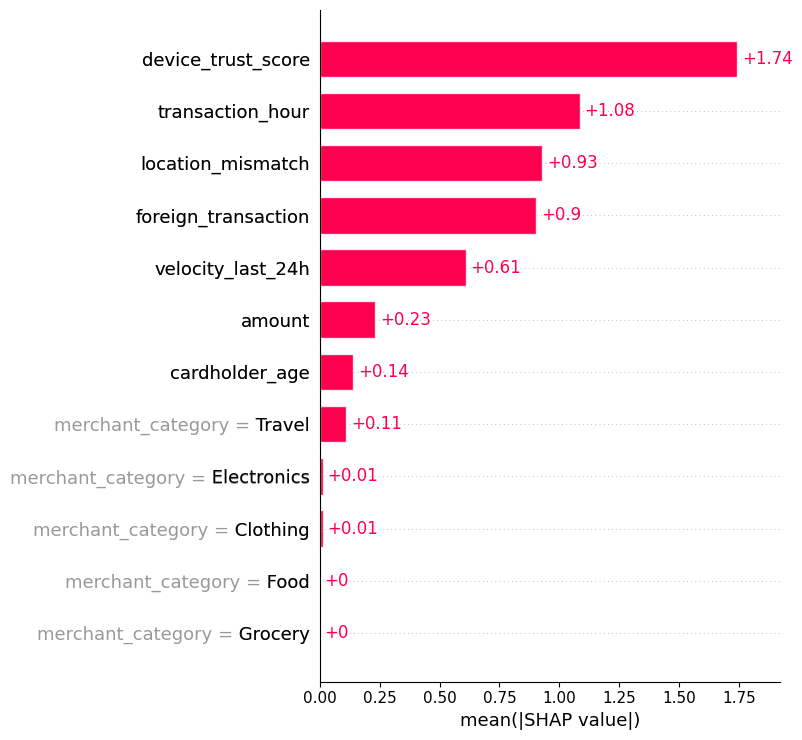

SHAP beeswarm: each point is a training transaction; color indicates feature value.


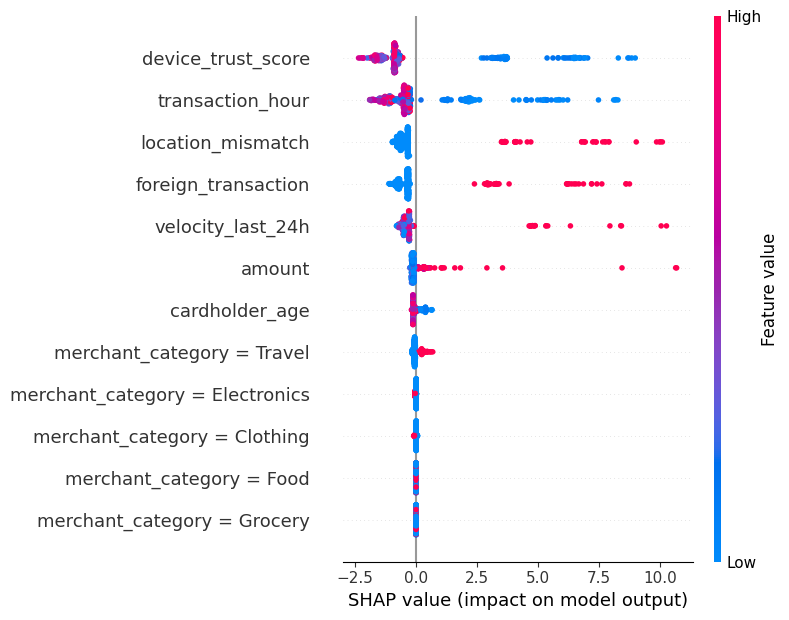

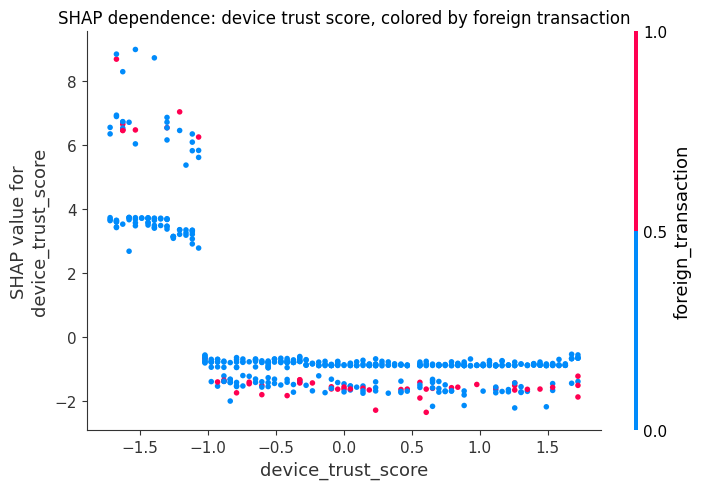

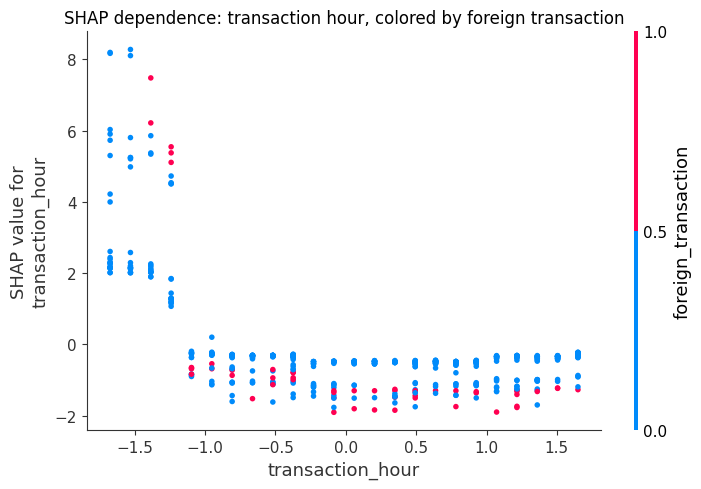

Correctly caught test fraud; transaction_id=8122; predicted fraud probability=0.9996


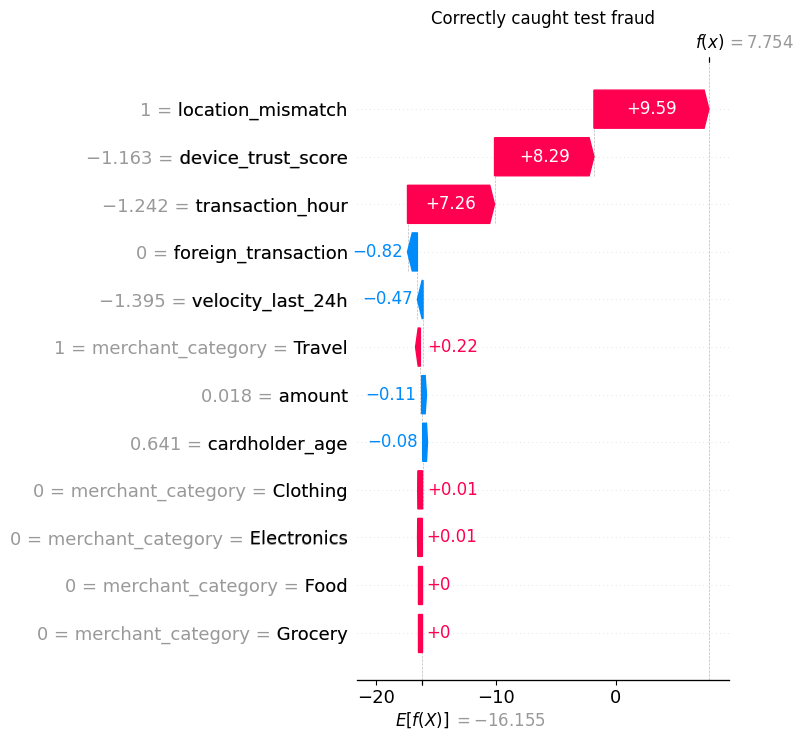

Missed test fraud; transaction_id=7657; predicted fraud probability=0.9629


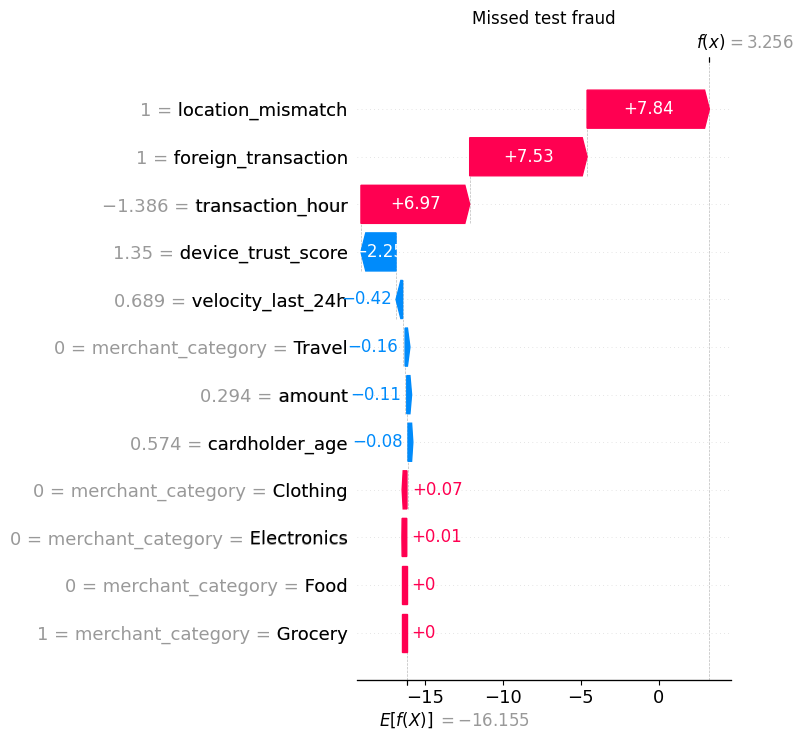

Low device trust is the training-set bottom quartile (score <= 44.0).
Training fraud rates by foreign transaction and low device trust:


,foreign_transaction,low_device_trust,transactions,fraud_count,fraud_rate
0,0,False,5309,6,0.001130
1,0,True,1903,51,0.026800
2,1,False,591,14,0.023689
3,1,True,197,50,0.253807


Training fraud rates by foreign transaction and night (hours 0-5):


,foreign_transaction,night,transactions,fraud_count,fraud_rate
0,0,False,5450,6,0.001101
1,0,True,1762,51,0.028944
2,1,False,594,19,0.031987
3,1,True,194,45,0.231959


Training-only CV comparison, including the interaction logistic model:


,ROC AUC mean,ROC AUC std,PR AUC mean,PR AUC std
model,,,,
Tuned Gradient Boosting,1.0000,0.0000,0.9979,0.0025
Gradient Boosting,0.9993,0.0007,0.9795,0.0089
Random Forest,0.9995,0.0005,0.9793,0.0221
Soft Voting,0.9996,0.0003,0.9777,0.0161
SVC,0.9961,0.0021,0.8216,0.1139
Logistic + pairwise interactions,0.9926,0.0039,0.7138,0.1066
Logistic Regression,0.9916,0.0033,0.6661,0.1034


Full-feature tuned-model CV PR AUC: 0.9979
Training-only one-feature-at-a-time ablation (diagnostic, not definitive proof of leakage):


,dropped feature,mean CV PR AUC,std CV PR AUC,change from full-feature CV
7,cardholder_age,0.9984,0.0015,0.0006
2,merchant_category,0.9933,0.0060,-0.0046
0,amount,0.9637,0.0252,-0.0342
4,location_mismatch,0.6640,0.1308,-0.3339
6,velocity_last_24h,0.6624,0.0819,-0.3354
3,foreign_transaction,0.6269,0.0617,-0.3710
5,device_trust_score,0.3890,0.0576,-0.6089
1,transaction_hour,0.3608,0.0391,-0.6370


Notebook cells that reference X_test or y_test:


,cell number,cell id,cell type,references and source lines
0,6,step-three-model-preparation,code,"{'X_test': [21], 'y_test': [21, 31, 32, 33, 34]}"
1,13,step-five-performance-report,code,"{'X_test': [71, 72, 123], 'y_test': [75, 107, ..."
2,15,b3cd323e,markdown,"{'X_test': [14], 'y_test': [14]}"
3,16,step-six-tuning-thresholds,code,"{'X_test': [219, 254, 266], 'y_test': [221, 22..."
4,18,step-seven-shap-and-diagnostics,code,"{'X_test': [87, 96, 99, 241, 253], 'y_test': [..."


In [8]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

if final_model_name != "Tuned Gradient Boosting":
    raise TypeError(
        "SHAP in this cell explains the tuned Gradient Boosting model selected in Step 6."
    )

# Refit the tuned tree pipeline on training data only.
step7_tree_pipeline = clone(tuned_pipeline_template).fit(X_train, y_train)
step7_preprocessor = step7_tree_pipeline.steps[0][1]
step7_tree_estimator = step7_tree_pipeline.steps[-1][1]

def dense_transformed_frame(preprocessor, frame, feature_names):
    transformed = preprocessor.transform(frame)
    if hasattr(transformed, "toarray"):
        transformed = transformed.toarray()
    return pd.DataFrame(transformed, columns=feature_names, index=frame.index)

raw_transformed_names = step7_preprocessor.get_feature_names_out()
readable_feature_names = []
for raw_name in raw_transformed_names:
    readable_name = str(raw_name).replace(
        "categorical__merchant_category_", "merchant_category = "
    )
    readable_name = readable_name.replace("continuous__", "").replace("binary__", "")
    readable_feature_names.append(readable_name)

shap_training_rows = X_train.sample(n=min(500, len(X_train)), random_state=42)
shap_training_matrix = dense_transformed_frame(
    step7_preprocessor,
    shap_training_rows,
    readable_feature_names,
)
tree_explainer = shap.TreeExplainer(step7_tree_estimator)
training_shap_values = tree_explainer(shap_training_matrix)

print("Global mean absolute SHAP importance (training sample):")
shap.plots.bar(training_shap_values, max_display=len(readable_feature_names), show=False)
plt.tight_layout()
plt.show()

print("SHAP beeswarm: each point is a training transaction; color indicates feature value.")
shap.plots.beeswarm(
    training_shap_values,
    max_display=len(readable_feature_names),
    show=False,
)
plt.tight_layout()
plt.show()

# Dependence plots use only training observations; color shows the paired feature.
shap.dependence_plot(
    "device_trust_score",
    training_shap_values.values,
    shap_training_matrix,
    interaction_index="foreign_transaction",
    show=False,
)
plt.title("SHAP dependence: device trust score, colored by foreign transaction")
plt.tight_layout()
plt.show()

shap.dependence_plot(
    "transaction_hour",
    training_shap_values.values,
    shap_training_matrix,
    interaction_index="foreign_transaction",
    show=False,
)
plt.title("SHAP dependence: transaction hour, colored by foreign transaction")
plt.tight_layout()
plt.show()

# Test rows are used only to select the requested explanation examples.
step7_test_probabilities = step7_tree_pipeline.predict_proba(X_test)[:, 1]
step7_test_predictions = (step7_test_probabilities >= final_threshold).astype(int)
test_labels_array = y_test.to_numpy()
caught_positions = np.flatnonzero((test_labels_array == 1) & (step7_test_predictions == 1))
missed_positions = np.flatnonzero((test_labels_array == 1) & (step7_test_predictions == 0))
if len(caught_positions) == 0 or len(missed_positions) == 0:
    raise ValueError("The test set must contain both a caught and a missed fraud for examples")

def explain_test_position(position, title):
    row_index = X_test.index[position]
    transformed_row = dense_transformed_frame(
        step7_preprocessor,
        X_test.iloc[[position]],
        readable_feature_names,
    )
    explanation = tree_explainer(transformed_row)
    transaction_id = int(df.loc[row_index, "transaction_id"])
    print(f"{title}; transaction_id={transaction_id}; predicted fraud probability="
          f"{step7_test_probabilities[position]:.4f}")
    shap.plots.waterfall(explanation[0], max_display=len(readable_feature_names), show=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

explain_test_position(int(caught_positions[0]), "Correctly caught test fraud")
explain_test_position(int(missed_positions[0]), "Missed test fraud")

# Cross-feature fraud rates, with cutoffs defined from training data only.
training_context = X_train[[
    "foreign_transaction", "device_trust_score", "transaction_hour"
]].copy()
training_context["is_fraud"] = y_train
low_trust_cutoff = X_train["device_trust_score"].quantile(0.25)
training_context["low_device_trust"] = (
    training_context["device_trust_score"] <= low_trust_cutoff
)
training_context["night"] = training_context["transaction_hour"].between(0, 5)

def fraud_rate_by_groups(frame, grouping_columns):
    return (
        frame.groupby(grouping_columns, observed=True)["is_fraud"]
        .agg(transactions="size", fraud_count="sum", fraud_rate="mean")
        .reset_index()
    )

print(f"Low device trust is the training-set bottom quartile (score <= {low_trust_cutoff:.1f}).")
print("Training fraud rates by foreign transaction and low device trust:")
display(fraud_rate_by_groups(
    training_context, ["foreign_transaction", "low_device_trust"]
))
print("Training fraud rates by foreign transaction and night (hours 0-5):")
display(fraud_rate_by_groups(training_context, ["foreign_transaction", "night"]))

# Compare logistic regression with tree models using the same training CV.
interaction_logistic_pipeline = make_pipeline(
    clone(preprocessor),
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    LogisticRegression(class_weight="balanced", max_iter=2000),
)
interaction_logistic_cv = cross_validate(
    interaction_logistic_pipeline,
    X_train,
    y_train,
    cv=stratified_cv,
    scoring=scoring,
    return_train_score=False,
)

cv_candidates = {
    **cv_results_by_model,
    "Tuned Gradient Boosting": tuned_cv_results,
    "Soft Voting": soft_voting_cv_results,
    "Logistic + pairwise interactions": interaction_logistic_cv,
}
cv_comparison_rows = []
for candidate_name, candidate_results in cv_candidates.items():
    cv_comparison_rows.append(
        {
            "model": candidate_name,
            "ROC AUC mean": candidate_results["test_roc_auc"].mean(),
            "ROC AUC std": candidate_results["test_roc_auc"].std(ddof=1),
            "PR AUC mean": candidate_results["test_pr_auc"].mean(),
            "PR AUC std": candidate_results["test_pr_auc"].std(ddof=1),
        }
    )
cv_model_comparison = pd.DataFrame(cv_comparison_rows).set_index("model").sort_values(
    "PR AUC mean", ascending=False
)
print("Training-only CV comparison, including the interaction logistic model:")
display(cv_model_comparison.round(4))

# Drop one original feature at a time; each fold refits preprocessing and the tuned model.
def preprocessor_without_feature(feature_to_drop):
    remaining_categorical = [
        column for column in categorical_columns if column != feature_to_drop
    ]
    remaining_continuous = [
        column for column in continuous_columns if column != feature_to_drop
    ]
    remaining_binary = [column for column in binary_columns if column != feature_to_drop]
    transformers = []
    if remaining_categorical:
        transformers.append(
            ("categorical", OneHotEncoder(handle_unknown="ignore"), remaining_categorical)
        )
    if remaining_continuous:
        transformers.append(("continuous", StandardScaler(), remaining_continuous))
    if remaining_binary:
        transformers.append(("binary", "passthrough", remaining_binary))
    return ColumnTransformer(transformers=transformers, remainder="drop")

tuned_tree_estimator = tuned_pipeline_template.steps[-1][1]
full_feature_cv_pr_auc = tuned_cv_results["test_pr_auc"].mean()
feature_drop_rows = []
for feature_to_drop in X_train.columns:
    reduced_X_train = X_train.drop(columns=[feature_to_drop])
    reduced_pipeline = make_pipeline(
        preprocessor_without_feature(feature_to_drop),
        clone(tuned_tree_estimator),
    )
    reduced_scores = cross_val_score(
        reduced_pipeline,
        reduced_X_train,
        y_train,
        cv=stratified_cv,
        scoring=scoring["pr_auc"],
    )
    feature_drop_rows.append(
        {
            "dropped feature": feature_to_drop,
            "mean CV PR AUC": reduced_scores.mean(),
            "std CV PR AUC": reduced_scores.std(ddof=1),
            "change from full-feature CV": reduced_scores.mean() - full_feature_cv_pr_auc,
        }
    )
feature_drop_summary = pd.DataFrame(feature_drop_rows).sort_values(
    "change from full-feature CV", ascending=False
)
print(f"Full-feature tuned-model CV PR AUC: {full_feature_cv_pr_auc:.4f}")
print("Training-only one-feature-at-a-time ablation (diagnostic, not definitive proof of leakage):")
display(feature_drop_summary.round(4))

# Scan the notebook after Step 7 so the list includes every analysis cell.
notebook_path = Path(csv_path).resolve().parent / "fraud_project.ipynb"
notebook_contents = json.loads(notebook_path.read_text(encoding="utf-8"))
test_variable_references = []
for cell_number, cell in enumerate(notebook_contents["cells"], start=1):
    cell_source_lines = "".join(cell.get("source", [])).splitlines()
    references = {
        variable: [
            line_number
            for line_number, line in enumerate(cell_source_lines, start=1)
            if variable in line
        ]
        for variable in ("X_test", "y_test")
    }
    references = {variable: lines for variable, lines in references.items() if lines}
    if references:
        test_variable_references.append(
            {
                "cell number": cell_number,
                "cell id": cell.get("id"),
                "cell type": cell.get("cell_type"),
                "references and source lines": references,
            }
        )
print("Notebook cells that reference X_test or y_test:")
display(pd.DataFrame(test_variable_references))

How to read the SHAP plots
A positive SHAP value pushes the model’s prediction toward fraud; a negative value pushes it toward legitimate. The global bar plot shows how influential features are on average, not which direction they push. The beeswarm shows direction: points to the right increase the fraud score, and color indicates low or high feature values.

The training-set interaction tables show especially strong combined patterns:

Foreign transaction + low device trust (score ≤44): fraud rate was 25.4%, versus 0.11% for domestic transactions with higher trust. Low trust or foreign status alone had much lower rates.
Foreign transaction + night (hours 0–5): 23.2%, versus 0.11% for domestic daytime transactions. Nighttime or foreign status alone had lower rates.
This supports an interaction: the combination is more concerning than either signal alone. Earlier EDA also pointed to nighttime transactions, low device trust, foreign transactions, location mismatch, and higher velocity as fraud-associated. Age and merchant category appear less useful.

Model comparison and leakage caution
On training-only CV, tuned gradient boosting had PR AUC 0.9979; random forest and the other gradient-boosting model were about 0.979. Logistic regression scored 0.666, and adding pairwise interactions raised it only to 0.714—still far below the trees.

Dropping features one at a time lowered PR AUC most when removing transaction hour (0.3608) or device trust (0.3890); dropping foreign transaction, velocity, or location mismatch also caused large declines. Dropping age barely changed performance (0.9984 vs. 0.9979 full-feature). This suggests several strong signals, not one single feature explaining the near-perfect score. Ablation is a warning check, not proof that leakage is absent.

The near-perfect CV performance is unusual for real fraud data, so I would treat this dataset as potentially synthetic or unusually separable and verify how its labels and features were generated. Also, the missed-fraud example had probability 0.9629 but was below the chosen 0.9989 threshold; the threshold’s OOF recall was only about 70%, so its stability is a concern.

These interpretations are from the Step 7 output in the notebook. The Step 7 SHAP examples use test cases for explanation, not for fitting or choosing settings; however, the test set was also examined in earlier steps, so it was not a pristine one-time holdout.

Yes—there’s strong descriptive evidence that these signals interact. Using training data, fraud rates were:

Transaction group	Fraud rate
Domestic, daytime	0.11%
Domestic, night (hours 0–5)	2.89%
Foreign, daytime	3.20%
Foreign, night	23.20%
Domestic, higher device trust	0.11%
Domestic, low device trust (≤44)	2.68%
Foreign, higher device trust	2.37%
Foreign, low device trust	25.38%
So foreign transactions are much riskier when they also happen at night or come from a low-trust device. These are associations in the training data, not proof of cause; the combined groups are relatively small.

On the same stratified 5-fold training CV, PR AUC was 0.666 for plain logistic regression and 0.714 for logistic regression with pairwise interactions. In comparison, it was 0.979 for random forest and the untuned gradient-boosting model, and 0.998 for tuned gradient boosting.

Plain logistic regression models mostly additive, linear effects unless interactions are explicitly added. Pairwise terms help, but trees can also learn nonlinear cutoffs and combinations of features, which likely explains much of the remaining gap. The near-perfect tree scores are unusually high for real fraud data, though, so treat them cautiously and investigate how this dataset was generated. These results are in the notebook.

Reran 5-fold CV on the training set after dropping each feature in turn:

Feature dropped	Mean CV PR AUC
cardholder age	0.9984
merchant category	0.9933
amount	0.9637
location mismatch	0.6640
velocity, last 24h	0.6624
foreign transaction	0.6269
device trust score	0.3890
transaction hour	0.3608

## Conclusion

**Selected model:** tuned HistGradientBoostingClassifier, selected over soft voting using training-only 5-fold CV PR AUC. Its reported CV results were PR AUC 0.9979 +/- 0.0025, ROC AUC 1.0000 +/- 0.0000, accuracy 0.9994 +/- 0.0006, balanced accuracy 0.9875 +/- 0.0114, precision 0.9837 +/- 0.0224, recall 0.9753 +/- 0.0225, and F1 0.9794 +/- 0.0204. Since Optuna tuning and this score use the same CV folds, the score may be optimistic.

**Threshold and final test result:** threshold 0.9989 was selected as the highest validation threshold that still achieved at least 90% fraud recall, prioritizing precision and fewer alerts under that recall constraint. On validation it had precision 1.00 and recall 0.90. On the final test evaluation it had precision 1.00, recall 0.833, F1 0.909, and accuracy 0.9975; the confusion matrix was TN=1970, FP=0, FN=5, TP=25. Training OOF recall at this threshold was only 0.703, so threshold stability is a concern.

**Main SHAP drivers:** on a 500-row training sample, the largest mean absolute SHAP values were device_trust_score (1.742), transaction_hour (1.085), location_mismatch (0.928), foreign_transaction (0.904), and velocity_last_24h (0.609). Low device trust, overnight hours, location mismatch, foreign transactions, and higher velocity generally push predictions toward fraud. Amount and cardholder age had smaller effects; merchant category effects were small overall.

**Interactions:** training fraud rates were 25.4% for foreign transactions with low device trust versus 2.4% for foreign transactions with higher trust; they were 23.2% for foreign transactions at night versus 3.2% for foreign daytime transactions. These are associations, not causal effects.

**Caution:** near-perfect CV performance is unusual for real fraud data. Feature ablation found several influential features but does not prove leakage is absent. The test set was also examined in earlier notebook steps and used for SHAP examples, so it is not an untouched holdout. Verify feature/label provenance and evaluate on fresh, preferably time- or customer-separated data before operational use.